# ¿Va a llegar tarde el pedido?

Actividad «Tu modelo, del notebook a train.py» con `data/raw/delivery_50000.csv`. Este notebook recorre las partes 1 a 8; el paso a `src/train.py` (partes 9 a 14) está en `NOTAS.md`. La limpieza y la tubería viven en `src/delivery.py`, que importan tanto este notebook como el script, para que los dos partan exactamente de lo mismo.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "8")  # en esta máquina (WSL) HistGradientBoosting se atasca con 16 hilos

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, accuracy_score)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     cross_validate, train_test_split)
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

import delivery
from delivery import SEMILLA, ENTRADA, OBJETIVO, FUTURO, tuberia
import train

pd.set_option("display.width", 160)

## 1 · La pregunta

**Respuesta 1.** Queremos predecir si un pedido **va a llegar tarde** (`llego_tarde`). La predicción se haría **en el momento en que la app confirma el pedido**, que es cuando calcula el tiempo prometido al cliente: si el modelo avisa de un retraso probable, todavía se puede reasignar un repartidor, ajustar el tiempo prometido o avisar al cliente. Es un problema de **clasificación binaria** (tarde / a tiempo). Predecir los minutos exactos sería una regresión, pero a la operación le basta con saber qué pedidos van a incumplir la promesa.

## 2 · Conocer los datos

In [2]:
crudo = delivery.cargar()
print(crudo.shape)
crudo.head()

(50180, 23)


,id_pedido,fecha_hora,zona,restaurante_id,tipo_comida,distancia_km,cantidad_items,importe,metodo_pago,cliente_nuevo,...,repartidores_disponibles,pedidos_activos_zona,vehiculo,tiempo_preparacion_estimado,tiempo_prometido_min,tiempo_real_min,llego_tarde,cancelado,propina,calificacion
0,1,2024-01-01 04:42,Afueras,R109,sushi,14.77,2,28.44,tarjeta,0,...,20.0,10,auto,22,75,74.6,0.0,0,0.00,5.0
1,2,2024-01-01 07:27,Centro,R030,pizza,3.96,1,12.23,efectivo,0,...,15.0,9,bici,15,35,33.4,0.0,0,0.93,4.0
2,3,2024-01-01 08:09,Centro,R007,pizza,2.53,4,43.53,tarjeta,0,...,21.0,13,moto,19,35,24.5,0.0,0,0.00,NaN
3,4,2024-01-01 08:14,Oeste,R034,pizza,8.89,3,28.97,efectivo,0,...,10.0,12,moto,18,55,45.5,0.0,0,0.00,NaN
4,5,2024-01-01 08:45,Sur,R131,china,1.96,4,35.46,tarjeta,0,...,15.0,7,moto,18,35,25.6,0.0,0,0.00,5.0


In [3]:
faltantes = crudo.isna().sum()
faltantes[faltantes > 0].to_frame("faltantes")

,faltantes
temperatura,600
repartidores_disponibles,301
tiempo_real_min,3130
llego_tarde,3130
calificacion,19482


In [4]:
print("Filas idénticas:", crudo.duplicated().sum())
print("id_pedido repetido:", crudo["id_pedido"].duplicated().sum())
repetidos = crudo[crudo["id_pedido"].duplicated(keep=False)]
distintos = repetidos[~repetidos.duplicated(keep=False)]
distintos.T

Filas idénticas: 179
id_pedido repetido: 180


,22611,22612
id_pedido,22526,22526
fecha_hora,2024-10-03 18:21,2024-10-03 18:21
zona,Norte,Norte
restaurante_id,R020,R020
tipo_comida,PIZZA,pizza
distancia_km,2.04,2.04
cantidad_items,1,1
importe,14.01,14.01
metodo_pago,tarjeta,tarjeta
cliente_nuevo,0,0


In [5]:
for col in ["zona", "tipo_comida", "metodo_pago", "clima", "vehiculo"]:
    print(col, crudo[col].value_counts().to_dict())
print("restaurante_id con formato R000:", crudo["restaurante_id"].str.fullmatch(r"R\d{3}").mean())

zona {'Centro': 10101, 'Norte': 7552, 'Sur': 7052, 'Este': 6565, 'Oeste': 5974, 'Universidad': 4903, 'Puerto': 4559, 'Afueras': 3474}
tipo_comida {'hamburguesas': 10155, 'pizza': 10014, 'china': 6040, 'sushi': 5952, 'mexicana': 5081, 'parrilla': 4970, 'saludable': 4776, 'postres': 3013, 'PIZZA': 35, 'HAMBURGUESAS': 34, 'PARRILLA': 22, 'MEXICANA': 21, 'CHINA': 19, 'SUSHI': 17, 'SALUDABLE': 16, 'POSTRES': 15}
metodo_pago {'tarjeta': 24981, 'app': 17711, 'efectivo': 7488}
clima {'despejado': 23953, 'nublado': 13742, 'lluvia': 9978, 'tormenta': 2507}
vehiculo {'moto': 23553, 'bici': 20585, 'auto': 6042}
restaurante_id con formato R000: 1.0


In [6]:
crudo.describe().T[["min", "50%", "max"]]

,min,50%,max
id_pedido,1.00,24996.50,50000.00
distancia_km,-6.41,2.40,18.00
cantidad_items,1.00,3.00,10.00
importe,0.00,27.09,167.51
cliente_nuevo,0.00,0.00,1.00
pedidos_previos,0.00,15.00,153.00
temperatura,-8.70,16.80,43.60
repartidores_disponibles,1.00,14.00,39.00
pedidos_activos_zona,0.00,24.00,70.00
tiempo_preparacion_estimado,8.00,16.00,35.00


In [7]:
print("distancia_km <= 0:", (crudo["distancia_km"] <= 0).sum())
print("importe <= 0:", (crudo["importe"] <= 0).sum())
print("tiempo_real_min = 999:", (crudo["tiempo_real_min"] == 999).sum(),
      "| siguiente máximo:", crudo.loc[crudo["tiempo_real_min"] < 999, "tiempo_real_min"].max())
print("Faltan tiempo_real_min y llego_tarde en los cancelados:")
pd.crosstab(crudo["cancelado"], crudo["llego_tarde"].isna(), rownames=["cancelado"], colnames=["llego_tarde vacío"])

distancia_km <= 0: 10
importe <= 0: 8
tiempo_real_min = 999: 7 | siguiente máximo: 146.2
Faltan tiempo_real_min y llego_tarde en los cancelados:


llego_tarde vacío,False,True
cancelado,,
0,47050,0
1,0,3130


In [8]:
# ¿Cómo se define llego_tarde? Retraso = tiempo real - tiempo prometido
retraso = crudo["tiempo_real_min"] - crudo["tiempo_prometido_min"]
validos = crudo["tiempo_real_min"] < 999
print("Retraso máximo con llego_tarde = 0:", retraso[validos & (crudo["llego_tarde"] == 0)].max())
print("Retraso mínimo con llego_tarde = 1:", retraso[validos & (crudo["llego_tarde"] == 1)].min())
print("Retraso de los 999 con llego_tarde = 0:", retraso[~validos & crudo["tiempo_real_min"].notna()].round(1).tolist())

Retraso máximo con llego_tarde = 0: 5.0
Retraso mínimo con llego_tarde = 1: 5.0
Retraso de los 999 con llego_tarde = 0: [944.0, 964.0, 974.0, 974.0, 974.0, 959.0, 954.0]


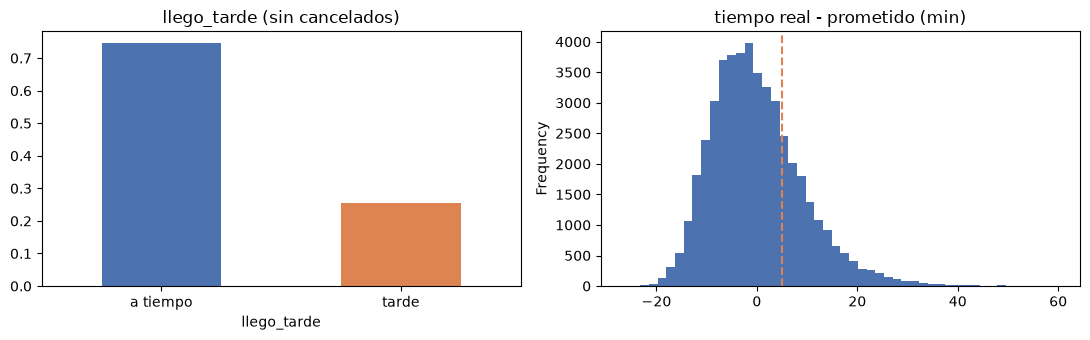

Proporción de pedidos tarde: 0.255


In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
crudo["llego_tarde"].value_counts(normalize=True).sort_index().plot.bar(ax=ejes[0], color=["#4C72B0", "#DD8452"])
ejes[0].set_title("llego_tarde (sin cancelados)"); ejes[0].set_xticklabels(["a tiempo", "tarde"], rotation=0)
retraso[validos].clip(-40, 60).plot.hist(bins=50, ax=ejes[1], color="#4C72B0")
ejes[1].axvline(5, color="#DD8452", ls="--"); ejes[1].set_title("tiempo real - prometido (min)")
plt.tight_layout(); plt.show()
print("Proporción de pedidos tarde:", round(crudo["llego_tarde"].mean(), 4))

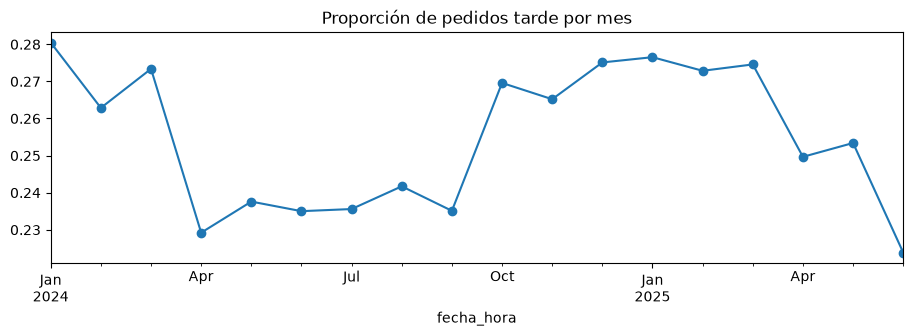

In [10]:
fecha = pd.to_datetime(crudo["fecha_hora"])
tarde_mes = crudo.groupby(fecha.dt.to_period("M"))["llego_tarde"].mean()
tarde_mes.plot(figsize=(11, 3), marker="o", title="Proporción de pedidos tarde por mes"); plt.show()

**Respuesta 2.** Problemas encontrados:

- **Repetidos:** 180 `id_pedido` aparecen dos veces. 179 son filas idénticas; el otro solo difiere en `tipo_comida` («PIZZA» frente a «pizza»), así que no se detecta mirando filas idénticas, hay que buscar por identificador.
- **Categorías mal escritas:** 179 filas de `tipo_comida` están en mayúsculas («PIZZA», «HAMBURGUESAS», etc.). El resto de categorías y el formato de `restaurante_id` (`R000`) están bien.
- **Valores imposibles:** 10 distancias negativas, 8 importes de 0 € con artículos en el pedido y 7 `tiempo_real_min = 999`. El 999 es un código de error: el siguiente máximo es 146,2 min, y esas filas tienen `llego_tarde = 0` con más de 940 min de retraso, así que su objetivo no es fiable. Las temperaturas (de −8,7 a 43,6 °C) son extremas pero posibles, y las dejamos.
- **Faltantes:** 600 `temperatura` y 301 `repartidores_disponibles`. `tiempo_real_min` y `llego_tarde` faltan exactamente en los 3.130 pedidos cancelados (nunca se entregaron). `calificacion` falta en 19.482, pero es una columna del futuro y no la usamos.
- **Objetivo:** el 25,5 % de los pedidos entregados llega tarde, así que está **desbalanceado** (3 a 1). La regla que sigue la columna es un retraso de más de 5 minutos sobre lo prometido: el retraso máximo con `llego_tarde = 0` y el mínimo con `llego_tarde = 1` son los dos 5,0 min. La proporción mensual se mueve entre el 22 % y el 28 % sin tendencia.

## 3 · Limpiar

In [11]:
datos, recuento = delivery.limpiar(crudo)
recuento

{'filas_originales': 50180,
 'pedidos_repetidos': 180,
 'distancia_no_positiva': 10,
 'importe_cero': 8,
 'cancelados': 3118,
 'tiempo_999': 7,
 'filas_finales': 46875}

In [12]:
print(datos.shape, "| proporción tarde:", round(datos[OBJETIVO].mean(), 4))
datos[["distancia_km", "importe", "temperatura", "repartidores_disponibles"]].isna().sum()

(46875, 23) | proporción tarde: 0.255


distancia_km                 10
importe                       8
temperatura                 557
repartidores_disponibles    283
dtype: int64

**Respuesta 3.** Lo que hicimos con cada problema (en `delivery.limpiar`, que usan el notebook y `train.py`):

- **Texto en minúsculas y sin espacios** antes de nada; así «PIZZA» y «pizza» son la misma categoría y el repetido que solo difería en eso aparece como repetido.
- **Repetidos:** nos quedamos con la primera aparición de cada `id_pedido` (−180 filas). Un pedido duplicado contaría dos veces en el entrenamiento y podría caer a la vez en entrenamiento y en prueba.
- **Distancias ≤ 0 e importes de 0:** los dejamos vacíos en lugar de borrar la fila. Son datos de entrada; en producción también puede llegar un pedido así, y la tubería los imputa con la mediana igual que a las temperaturas y repartidores que faltan.
- **Filas que no sirven para esta pregunta:** los **3.118 cancelados** (tras quitar repetidos) no tienen entrega, así que no se sabe si habrían llegado tarde, y los **7 pedidos con tiempo 999**, cuyo `llego_tarde` contradice la regla del resto.

Quedan **46.875 pedidos** con un 25,5 % tarde.

## 4 · Elegir las columnas

In [13]:
print("Del futuro (fuera):", FUTURO)
print("Identificador (fuera): id_pedido")
print("Entrada de la tubería:", ENTRADA)
print("Derivadas dentro de la tubería:", delivery.DERIVADAS)

Del futuro (fuera): ['tiempo_real_min', 'llego_tarde', 'cancelado', 'propina', 'calificacion']
Identificador (fuera): id_pedido
Entrada de la tubería: ['fecha_hora', 'zona', 'restaurante_id', 'tipo_comida', 'metodo_pago', 'clima', 'vehiculo', 'distancia_km', 'cantidad_items', 'importe', 'cliente_nuevo', 'pedidos_previos', 'temperatura', 'repartidores_disponibles', 'pedidos_activos_zona', 'tiempo_preparacion_estimado', 'tiempo_prometido_min']
Derivadas dentro de la tubería: ['hora', 'dia_semana', 'mes', 'pedidos_por_repartidor', 'margen_reparto_min']


In [14]:
# Comprobación: sin columnas del futuro y la tubería transforma pedidos crudos
assert not set(FUTURO) & set(ENTRADA)
X, y = datos[ENTRADA], datos[OBJETIVO]
delivery.anadir_derivadas(X.head(3))

,zona,restaurante_id,tipo_comida,metodo_pago,clima,vehiculo,distancia_km,cantidad_items,importe,cliente_nuevo,...,temperatura,repartidores_disponibles,pedidos_activos_zona,tiempo_preparacion_estimado,tiempo_prometido_min,hora,dia_semana,mes,pedidos_por_repartidor,margen_reparto_min
0,afueras,R109,sushi,tarjeta,despejado,auto,14.77,2,28.44,0,...,10.9,20.0,10,22,75,4,0,1,0.500000,53
1,centro,R030,pizza,efectivo,despejado,bici,3.96,1,12.23,0,...,14.5,15.0,9,15,35,7,0,1,0.600000,20
2,centro,R007,pizza,tarjeta,despejado,moto,2.53,4,43.53,0,...,11.5,21.0,13,19,35,8,0,1,0.619048,16


**Respuesta 4.** Al confirmar el pedido todavía no se conocen `tiempo_real_min`, `llego_tarde`, `cancelado`, `propina` ni `calificacion`: son datos del futuro y usarlos sería hacer trampa (el tiempo real, por ejemplo, define directamente el objetivo). `id_pedido` tampoco entra porque es un identificador sin significado.

Características finales: `zona`, `restaurante_id`, `tipo_comida`, `metodo_pago`, `clima`, `vehiculo`, `distancia_km`, `cantidad_items`, `importe`, `cliente_nuevo`, `pedidos_previos`, `temperatura`, `repartidores_disponibles`, `pedidos_activos_zona`, `tiempo_preparacion_estimado` y `tiempo_prometido_min`. A partir de `fecha_hora` y de esas columnas, la tubería calcula `hora`, `dia_semana`, `mes`, `pedidos_por_repartidor` (pedidos activos / repartidores) y `margen_reparto_min` (prometido − preparación).

Supuesto que conviene confirmar: el enunciado agrupa `vehiculo` con el estado de la operación, así que asumimos que el repartidor (y su vehículo) ya está asignado al confirmar. Si se asignara después, habría que sacarlo.

## 5 · Separar y la línea base

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA)
print(len(X_train), len(X_test), round(y_train.mean(), 4), round(y_test.mean(), 4))
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)

37500 9375 0.255 0.255


In [16]:
# Línea base sin modelo: decir siempre «a tiempo» (la clase mayoritaria)
base = DummyClassifier(strategy="prior").fit(X_train, y_train)
proba_base = base.predict_proba(X_test)[:, 1]
pred_base = base.predict(X_test)
print("Exactitud:", round(accuracy_score(y_test, pred_base), 4))
print("Recall de 'tarde':", recall_score(y_test, pred_base))
print("Precisión media (AP):", round(average_precision_score(y_test, proba_base), 4))

Exactitud: 0.745
Recall de 'tarde': 0.0
Precisión media (AP): 0.255


**Respuesta 5.** Separamos 80/20 estratificado por el objetivo con `random_state=42` (37.500 pedidos de entrenamiento y 9.375 de prueba, los dos con un 25,5 % tarde). Sobre la prueba solo medimos aquí la línea base, que no se elige con ella; el modelo no la ve hasta el paso 8.

Sin modelo, lo mejor que se puede hacer es decir siempre «a tiempo»: **exactitud 0,745** y recall 0. Por eso la exactitud no sirve aquí: un modelo que no detecta ningún retraso ya acierta el 74,5 %.

Métrica principal: **precisión media (AP, área bajo la curva precisión-recall)** de la clase «tarde». No depende del umbral, se fija en la clase minoritaria y su valor sin modelo es la proporción de positivos (**0,255**). Para el modelo final también damos recall, precisión y F1 con un umbral concreto.

## 6 · Comparar modelos

In [17]:
candidatos = {
    "línea base": tuberia(DummyClassifier(strategy="prior")),
    "regresión logística": tuberia(LogisticRegression(max_iter=2000, class_weight="balanced"), escalar=True),
    "árbol de decisión": tuberia(DecisionTreeClassifier(max_depth=8, random_state=SEMILLA)),
    "random forest": tuberia(RandomForestClassifier(n_estimators=300, n_jobs=8, random_state=SEMILLA)),
    "hist gradient boosting": tuberia(HistGradientBoostingClassifier(random_state=SEMILLA)),
    "xgboost": tuberia(XGBClassifier(n_jobs=8, random_state=SEMILLA)),
}
filas = []
for nombre, modelo in candidatos.items():
    inicio = time.time()
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=["average_precision", "roc_auc"])
    filas.append({"modelo": nombre,
                  "AP media": r["test_average_precision"].mean(), "AP desv.": r["test_average_precision"].std(),
                  "ROC AUC media": r["test_roc_auc"].mean(), "segundos": time.time() - inicio})
comparacion = pd.DataFrame(filas).sort_values("AP media", ascending=False).round(4)
comparacion

,modelo,AP media,AP desv.,ROC AUC media,segundos
4,hist gradient boosting,0.8014,0.0050,0.9062,16.3353
5,xgboost,0.7927,0.0045,0.9021,4.2913
3,random forest,0.7826,0.0067,0.8971,28.2819
1,regresión logística,0.7750,0.0054,0.8919,4.6315
2,árbol de decisión,0.7312,0.0050,0.8803,6.6236
0,línea base,0.2550,0.0001,0.5000,1.7193


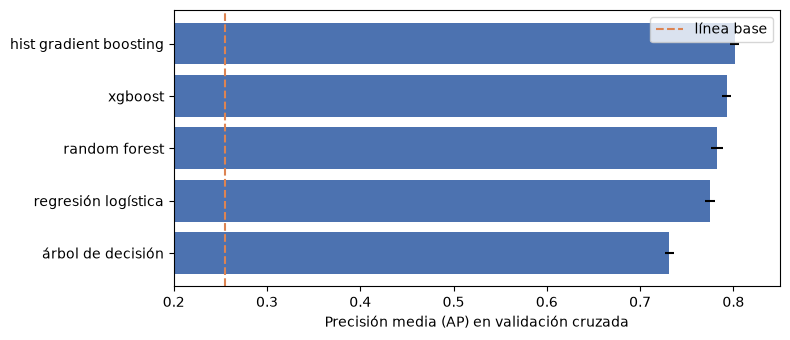

In [18]:
c = comparacion[comparacion["modelo"] != "línea base"].iloc[::-1]
plt.figure(figsize=(8, 3.5))
plt.barh(c["modelo"], c["AP media"], xerr=c["AP desv."], color="#4C72B0")
plt.axvline(comparacion.loc[comparacion["modelo"] == "línea base", "AP media"].item(), color="#DD8452", ls="--", label="línea base")
plt.xlim(0.2, 0.85); plt.xlabel("Precisión media (AP) en validación cruzada"); plt.legend(); plt.tight_layout(); plt.show()

**Respuesta 6.** Con validación cruzada estratificada de 5 folds sobre el entrenamiento, **los cinco modelos le ganan con mucho a la línea base** (AP 0,255):

| Modelo | AP media ± desv. |
|---|---|
| HistGradientBoosting | 0,801 ± 0,005 |
| XGBoost | 0,793 ± 0,005 |
| Random forest | 0,783 ± 0,007 |
| Regresión logística | 0,775 ± 0,005 |
| Árbol de decisión (profundidad 8) | 0,731 ± 0,005 |

- Los dos boosting quedan por delante: les separan 0,009, casi dos desviaciones, así que por defecto HistGradientBoosting es algo mejor.
- Random forest y regresión logística están **prácticamente empatados**: 0,008 de diferencia con desviaciones de 0,005 a 0,007.
- El árbol solo queda claramente por detrás.
- Pasamos a ajustar los dos boosting: están arriba y el margen entre ellos es pequeño.

## 7 · Ajustar los hiperparámetros

In [19]:
espacios = {
    "hist gradient boosting": (HistGradientBoostingClassifier(random_state=SEMILLA), {
        "modelo__learning_rate": loguniform(0.02, 0.3), "modelo__max_iter": randint(100, 800),
        "modelo__max_leaf_nodes": randint(8, 64), "modelo__min_samples_leaf": randint(10, 200),
        "modelo__l2_regularization": loguniform(1e-3, 10)}),
    "xgboost": (XGBClassifier(n_jobs=8, random_state=SEMILLA), {
        "modelo__n_estimators": randint(100, 800), "modelo__learning_rate": loguniform(0.01, 0.3),
        "modelo__max_depth": randint(2, 9), "modelo__subsample": uniform(0.5, 0.5),
        "modelo__colsample_bytree": uniform(0.4, 0.6), "modelo__min_child_weight": randint(1, 20)}),
}
aleatorias = {}
for nombre, (modelo, espacio) in espacios.items():
    busqueda = RandomizedSearchCV(tuberia(modelo), espacio, n_iter=30, cv=cv, scoring="average_precision",
                                  random_state=SEMILLA, refit=False).fit(X_train, y_train)
    aleatorias[nombre] = pd.DataFrame(busqueda.cv_results_).sort_values("rank_test_score")
    mejor = aleatorias[nombre].iloc[0]
    print(f"{nombre}: AP {mejor['mean_test_score']:.4f} ± {mejor['std_test_score']:.4f}")

hist gradient boosting: AP 0.8038 ± 0.0049


xgboost: AP 0.8045 ± 0.0057


In [20]:
def tabla(resultados, n=8):
    cols = [c for c in resultados if c.startswith("param_")]
    t = resultados[cols + ["mean_test_score", "std_test_score"]].copy()
    t.columns = [c.replace("param_modelo__", "") for c in cols] + ["AP media", "AP desv."]
    return t.head(n).round(4)

tabla(aleatorias["xgboost"])

,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,subsample,AP media,AP desv.
7,0.4096,0.0219,5,15,554,0.8050,0.8045,0.0057
5,0.7710,0.0367,5,3,584,0.8038,0.8044,0.0053
17,0.5648,0.0675,4,5,561,0.9245,0.8042,0.0052
18,0.8330,0.0223,7,7,492,0.8553,0.8040,0.0050
9,0.5870,0.0586,3,4,576,0.9848,0.8038,0.0056
1,0.4936,0.0122,6,4,763,0.8254,0.8038,0.0056
29,0.8084,0.0608,3,6,515,0.7963,0.8036,0.0053
24,0.5368,0.0427,5,13,358,0.5035,0.8036,0.0052


In [21]:
tabla(aleatorias["hist gradient boosting"])

,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,AP media,AP desv.
14,5.0890,0.1433,370,15,199,0.8038,0.0049
24,0.1233,0.0637,653,20,188,0.8038,0.0052
1,0.2440,0.0669,314,18,97,0.8033,0.0052
2,0.0216,0.0294,230,29,62,0.8029,0.0056
5,0.0398,0.0227,799,23,24,0.8029,0.0053
8,0.0048,0.0239,487,32,69,0.8028,0.0052
17,0.0153,0.0313,620,31,138,0.8027,0.0054
29,0.0670,0.0361,439,37,199,0.8027,0.0051


In [22]:
# Cuadrícula pequeña alrededor del mejor XGBoost de la búsqueda aleatoria
cuadricula = {
    "modelo__max_depth": [4, 5, 6],
    "modelo__learning_rate": [0.02, 0.04],
    "modelo__min_child_weight": [5, 15],
    "modelo__colsample_bytree": [0.4, 0.6],
    "modelo__n_estimators": [550],
    "modelo__subsample": [0.8],
}
busqueda_cuadricula = GridSearchCV(tuberia(XGBClassifier(n_jobs=8, random_state=SEMILLA)), cuadricula,
                                   cv=cv, scoring="average_precision", refit=False).fit(X_train, y_train)
resultados_cuadricula = pd.DataFrame(busqueda_cuadricula.cv_results_).sort_values("rank_test_score")
tabla(resultados_cuadricula, 10)

,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,subsample,AP media,AP desv.
19,0.6,0.04,4,15,550,0.8,0.8059,0.0060
17,0.6,0.02,6,15,550,0.8,0.8057,0.0052
7,0.4,0.04,4,15,550,0.8,0.8055,0.0054
15,0.6,0.02,5,15,550,0.8,0.8052,0.0056
21,0.6,0.04,5,15,550,0.8,0.8049,0.0051
9,0.4,0.04,5,15,550,0.8,0.8047,0.0050
16,0.6,0.02,6,5,550,0.8,0.8047,0.0050
18,0.6,0.04,4,5,550,0.8,0.8047,0.0052
5,0.4,0.02,6,15,550,0.8,0.8044,0.0053
14,0.6,0.02,5,5,550,0.8,0.8043,0.0054


In [23]:
# Variación por fold de los cinco mejores de la cuadrícula
folds = [f"split{i}_test_score" for i in range(5)]
resultados_cuadricula[folds].head(5).round(4)

,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score
19,0.8076,0.7942,0.8093,0.8111,0.8073
17,0.8075,0.7956,0.8083,0.8103,0.8068
7,0.8068,0.7950,0.8090,0.8102,0.8062
15,0.8065,0.7945,0.8077,0.8106,0.8068
21,0.8077,0.7948,0.8082,0.8081,0.8058


In [24]:
print("Hiperparámetros del modelo final (src/train.py):", train.HIPERPARAMETROS)
final_cv = cross_validate(train.modelo_final(), X_train, y_train, cv=cv, scoring="average_precision")
xgb_defecto = comparacion.set_index("modelo").loc["xgboost"]
print(f"XGBoost por defecto: AP {xgb_defecto['AP media']:.4f} ± {xgb_defecto['AP desv.']:.4f}")
print(f"XGBoost ajustado:    AP {final_cv['test_score'].mean():.4f} ± {final_cv['test_score'].std():.4f}")

Hiperparámetros del modelo final (src/train.py): {'n_estimators': 550, 'learning_rate': 0.04, 'max_depth': 4, 'min_child_weight': 15, 'subsample': 0.8, 'colsample_bytree': 0.6}


XGBoost por defecto: AP 0.7927 ± 0.0045
XGBoost ajustado:    AP 0.8059 ± 0.0060


**Respuesta 7.**

**Búsqueda aleatoria de 30 combinaciones por modelo.**
- En **XGBoost** variamos `n_estimators`, `learning_rate`, `max_depth`, `subsample`, `colsample_bytree` y `min_child_weight`.
- En **HistGradientBoosting** variamos `learning_rate`, `max_iter`, `max_leaf_nodes`, `min_samples_leaf` y `l2_regularization`.
- Resultado: los dos acaban en la misma meseta, XGBoost con 0,8045 y HistGradientBoosting con 0,8038.

**Cuadrícula pequeña alrededor del mejor XGBoost.** Probamos 24 combinaciones. La mejor es `max_depth=4`, `learning_rate=0.04`, `min_child_weight=15`, `colsample_bytree=0.6`, `subsample=0.8` y `n_estimators=550`.

**Lo que se ve en la cuadrícula:**
- Las diez primeras están a menos de 0,002 entre sí, muy por debajo de la desviación: es una meseta.
- `min_child_weight=15`, que pide hojas con más pedidos, aparece en las seis primeras, y la profundidad entre 4 y 6 da igual.
- Por folds, todas suben y bajan juntas: el fold 2 da ~0,795 a todas y el resto ~0,807. La variación viene de qué pedidos caen en cada fold, no de un candidato inestable.

**Cuánto mejoró el finalista.**

| XGBoost | AP media ± desv. |
|---|---|
| Por defecto | 0,7927 ± 0,0045 |
| Ajustado | 0,8059 ± 0,0060 |

- La mejora es de **+0,013, unas dos desviaciones**: sí es mayor que la desviación.
- En cambio, frente al mejor modelo sin ajustar (HistGradientBoosting, 0,8014) la ganancia es de solo +0,0045, por debajo de la desviación. Ajustar ha servido sobre todo para que XGBoost alcance esa meseta.
- Elegimos el XGBoost de la cuadrícula porque es el de mayor media y es el más rápido: unos 4 s por validación cruzada por defecto, frente a 16 s.

## 8 · El examen final

In [25]:
umbral = train.umbral_decision(train.modelo_final(), X_train, y_train)
modelo = train.modelo_final().fit(X_train, y_train)
proba = modelo.predict_proba(X_test)[:, 1]
pred = proba >= umbral
print("Umbral de decisión elegido con validación cruzada en entrenamiento:", umbral)
examen = pd.DataFrame({
    "línea base": {"AP": average_precision_score(y_test, proba_base), "ROC AUC": roc_auc_score(y_test, proba_base),
                   "exactitud": accuracy_score(y_test, pred_base), "recall": recall_score(y_test, pred_base),
                   "precisión": precision_score(y_test, pred_base, zero_division=0), "F1": f1_score(y_test, pred_base)},
    "modelo": {"AP": average_precision_score(y_test, proba), "ROC AUC": roc_auc_score(y_test, proba),
               "exactitud": accuracy_score(y_test, pred), "recall": recall_score(y_test, pred),
               "precisión": precision_score(y_test, pred), "F1": f1_score(y_test, pred)},
}).round(4)
examen

Umbral de decisión elegido con validación cruzada en entrenamiento: 0.36


,línea base,modelo
AP,0.255,0.8132
ROC AUC,0.500,0.9122
exactitud,0.745,0.8487
recall,0.000,0.7394
precisión,0.000,0.6898
F1,0.000,0.7138


In [26]:
pd.DataFrame(confusion_matrix(y_test, pred), index=["real: a tiempo", "real: tarde"],
             columns=["pred: a tiempo", "pred: tarde"])

,pred: a tiempo,pred: tarde
real: a tiempo,6189,795
real: tarde,623,1768


In [27]:
# ¿Dónde se equivoca más? Error por segmento en la prueba
prueba = X_test.assign(real=y_test.values, pred=pred.astype(int), proba=proba)
prueba["error"] = prueba["real"] != prueba["pred"]
prueba["falso_negativo"] = (prueba["real"] == 1) & (prueba["pred"] == 0)
prueba["falso_positivo"] = (prueba["real"] == 0) & (prueba["pred"] == 1)
prueba["hora"] = pd.to_datetime(prueba["fecha_hora"]).dt.hour
prueba["franja_distancia"] = pd.cut(prueba["distancia_km"], [0, 1, 2, 4, 8, 20])
prueba["franja_prob"] = pd.cut(prueba["proba"], [0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True)

def por(col):
    g = prueba.groupby(col, observed=True)
    return pd.DataFrame({"pedidos": g.size(), "% tarde real": g["real"].mean(), "error": g["error"].mean(),
                         "falsos neg.": g["falso_negativo"].sum(), "falsos pos.": g["falso_positivo"].sum()}).round(3)

por("franja_prob")

,pedidos,% tarde real,error,falsos neg.,falsos pos.
franja_prob,,,,,
"(-0.001, 0.2]",5646,0.055,0.055,308,0
"(0.2, 0.4]",1373,0.290,0.320,315,124
"(0.4, 0.6]",836,0.472,0.528,0,441
"(0.6, 0.8]",569,0.703,0.297,0,169
"(0.8, 1.0]",951,0.936,0.064,0,61


In [28]:
por("clima")

,pedidos,% tarde real,error,falsos neg.,falsos pos.
clima,,,,,
despejado,4523,0.176,0.150,348,332
lluvia,1776,0.527,0.160,80,205
nublado,2680,0.161,0.144,178,207
tormenta,396,0.581,0.172,17,51


In [29]:
por("vehiculo")

,pedidos,% tarde real,error,falsos neg.,falsos pos.
vehiculo,,,,,
auto,1122,0.320,0.176,47,150
bici,3762,0.326,0.188,260,447
moto,4491,0.179,0.114,316,198


In [30]:
por("zona").sort_values("error", ascending=False)

,pedidos,% tarde real,error,falsos neg.,falsos pos.
zona,,,,,
centro,1872,0.261,0.163,137,169
norte,1390,0.267,0.158,104,115
universidad,895,0.251,0.153,73,64
oeste,1117,0.240,0.150,75,93
puerto,885,0.241,0.150,44,89
sur,1319,0.249,0.149,80,117
este,1265,0.236,0.142,74,105
afueras,632,0.312,0.125,36,43


In [31]:
por("franja_distancia")

,pedidos,% tarde real,error,falsos neg.,falsos pos.
franja_distancia,,,,,
"(0, 1]",1428,0.221,0.152,110,107
"(1, 2]",2429,0.230,0.150,176,189
"(2, 4]",3388,0.262,0.159,220,318
"(4, 8]",1788,0.298,0.154,104,171
"(8, 20]",341,0.284,0.067,13,10


**Respuesta 8.** Medido una sola vez en los 9.375 pedidos de prueba:

| Métrica | Línea base | Modelo |
|---|---|---|
| AP | 0,255 | **0,813** |
| ROC AUC | 0,500 | 0,912 |
| Exactitud | 0,745 | 0,849 |

El 0,813 de la prueba está en línea con el 0,806 de la validación cruzada, así que la búsqueda no se ha sobreajustado a los folds.

**Umbral de decisión.** Usamos **0,36**, el que maximiza F1 en las predicciones fuera de fold del entrenamiento; la prueba no interviene en elegirlo. Con ese umbral:
- recall 0,739, precisión 0,690 y F1 0,714;
- detecta **1.768 de los 2.391 retrasos**, se le escapan 623 y da 795 falsas alarmas.

**Dónde se equivoca más:**
- **Probabilidades intermedias.** Entre 0,4 y 0,6 falla el 53 % de los pedidos, y entre 0,2 y 0,4, el 32 %. Por encima de 0,8 o por debajo de 0,2 solo falla un 6 %. Casi todos los retrasos que se escapan (623) tienen probabilidad por debajo de 0,4: son pedidos que, con los datos de la confirmación, parecían normales.
- **Bici.** Es el vehículo con más error (18,8 %), frente a 11,4 % de la moto.
- **Lluvia y tormenta.** Fallan algo más que con buen tiempo (16-17 % frente a 14-15 %), y ahí más de la mitad de los pedidos llegan tarde.
- **Zonas.** Están parejas, entre el 12,5 % y el 16,3 % de error.
- **Distancias largas.** Por encima de 8 km apenas falla (6,7 %).

Para mejorar haría falta información que hoy no está en la tabla, como el retraso real de la cocina o el tráfico.